BooT i.e. Built of off Time is a custom LLM designed from scratch.

In [ ]:
!pip install tiktoken

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F

In [ ]:
batch_size = 64
lr = 3e-4
n_embed = 768
device = ("cuda"
          if torch.cuda.is_available()
          else "cpu")
n_layers = 12
n_head = 12
block_size = 1024
epochs = 15000
warmup_steps = 300

In [ ]:
torch.manual_seed(42)

In [ ]:
from datasets import load_dataset

dataset = load_dataset("HuggingFaceFW/fineweb-edu", "sample-10BT", split="train", streaming=True)

README.md:   0%|          | 0.00/26.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

In [ ]:
import tiktoken

enc = tiktoken.get_encoding('gpt2')
encoder = lambda s: enc.encode(s, allowed_special={"<|endoftext|>"})
decoder = lambda l: enc.decode(l)
vocab_size = enc.n_vocab
vocab_size

50257

In [ ]:
target_tokens = 3_000_000_000
one_dim_tokens = []

for item in dataset:
    tokens = encoder(item["text"])
    one_dim_tokens.extend(tokens)

    if len(one_dim_tokens) >= target_tokens:
      break

data = torch.tensor(one_dim_tokens, dtype=torch.long)
print(len(data))

In [ ]:
with open('content/drive/MyDrive/', 'w', encoding='utf-8') as f:
  f.write()

In [ ]:
# train/test split
n = int(0.9*len(data))
train_data = data[:n]
test_data = data[n:]

print(len(train_data))
print(len(test_data))

180001439
20000160


In [ ]:
class SwiGLU(nn.Module):

  def __init__(self, d_model, d_ffn, dropout=0.1):
    super().__init__()

    hidden_dim = int(2 * d_ffn / 3)

    self.w1 = nn.Linear(d_model, hidden_dim, bias=False)
    self.w2 = nn.Linear(d_model, hidden_dim, bias=False)
    self.w3 = nn.Linear(hidden_dim, d_model, bias=False)
    self.dropout = nn.Dropout(dropout)

  def forward(self, x):

    gate = F.silu(self.w1(x))
    data = self.w2(x)
    return self.dropout(self.w3(gate * data))

In [ ]:
class Embeddings(nn.Module):
  def __init__(self, vocab_size, embed_dim, block_size):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embed_dim)
    self.pos_enc = nn.Embedding(block_size, embed_dim)

  def forward(self, x):
    B, T = x.size()
    word_embedding = self.embedding(x)
    positions = torch.arange(T, device=x.device)
    pos_embed = self.pos_enc(positions)
    return word_embedding + pos_embed

class MultiHeadAttention(nn.Module):
  def __init__(self, embed_dim, num_heads, context_size, dropout=0.1):
    super().__init__()

    assert embed_dim % num_heads == 0
    self.num_heads = num_heads
    self.head_dim = embed_dim // num_heads
    self.qkv = nn.Linear(embed_dim, 3 * embed_dim, bias=False)
    self.proj = nn.Linear(embed_dim, embed_dim, bias=False)
    self.dropout_p = dropout
    self.resid_dropout = nn.Dropout(dropout)

  def forward(self, x):
    B, T, C = x.size()
    qkv = self.qkv(x)
    q, k, v = qkv.split(C, dim=2)
    q = q.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
    k = k.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
    v = v.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
    out = F.scaled_dot_product_attention(
      q, k, v, is_causal=True,
      dropout_p=self.dropout_p if self.training else 0.0
    )
    out = out.transpose(1, 2).contiguous().view(B, T, C)

    return self.resid_dropout(self.proj(out))



In [ ]:
class Block(nn.Module):
  def __init__(self, n_embed, n_head, block_size):
    super().__init__()
    self.self_attn = MultiHeadAttention(n_embed, n_head, block_size)
    self.ffwd = SwiGLU(n_embed, 4 * n_embed)
    self.ln1 = nn.LayerNorm(n_embed)
    self.ln2 = nn.LayerNorm(n_embed)

  def forward(self, x):
    x = x + self.self_attn(self.ln1(x))
    x = x + self.ffwd(self.ln2(x))
    return x

In [ ]:
def get_batches(split):
  data = train_data if split == 'train' else test_data
  ix = torch.randint(len(data) - block_size, (batch_size,))
  x = torch.stack([data[i:i+block_size] for i in ix])
  y = torch.stack([data[i+1:i+block_size+1] for i in ix])
  x, y = x.to(device), y.to(device)
  return x, y


In [ ]:
class BooT(nn.Module):
  def __init__(self, vocab_size, n_embed, n_head, n_layers, block_size):
    super().__init__()

    self.block_size = block_size
    self.embeddings = Embeddings(vocab_size, n_embed, block_size)
    self.blocks = nn.ModuleList([Block(n_embed, n_head, block_size) for _ in range(n_layers)])
    self.lnm = nn.LayerNorm(n_embed)
    self.lm_head = nn.Linear(n_embed, vocab_size)
    self.lm_head.weight = self.embeddings.embedding.weight

  def forward(self, x, targets=None):
    x = self.embeddings(x)
    for block in self.blocks:
      x = block(x)
    x = self.lnm(x)
    logits = self.lm_head(x)

    loss = None
    if targets is not None:
      B, T, V = logits.size()
      loss = F.cross_entropy(logits.view(B*T, V), targets.view(B*T))

    return logits, loss

  @torch.no_grad()
  def generate(self, idx, max_new_tokens, temperature=0.8, top_k=40):
    self.eval()
    for _ in range(max_new_tokens):
      idx_cond = idx[:, -self.block_size:]
      logits, _ = self(idx_cond)
      logits = logits[:, -1, :] / temperature

      if top_k is not None:
        v, _ = torch.topk(logits, top_k)
        logits[logits < v[:, [-1]]] = float('-inf')

      probs = F.softmax(logits, dim=-1)
      next_token = torch.multinomial(probs, num_samples=1)
      idx = torch.cat((idx, next_token), dim=1)
    self.train()
    return idx

In [ ]:
model = BooT(vocab_size, n_embed, n_head, n_layers, block_size)
model.to(device)

print(sum(p.numel() for p in model.parameters()) / 1e6, "M parameters")

model = torch.compile(model)
optim = torch.optim.AdamW(model.parameters(), lr=lr)

def lr_lambda(step):
    if step < warmup_steps:
        return step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, epochs - warmup_steps)
    return 0.5 * (1 + torch.cos(torch.tensor(progress * 3.14159265)))

sched = torch.optim.lr_scheduler.LambdaLR(optim, lr_lambda)

177.627217 M parameters


In [ ]:
@torch.no_grad()
def estimate_val_loss(batches=20):
  model.eval()
  losses = []
  for _ in range(batches):
    x, y = get_batches("test")
    _, loss = model(x, y)
    losses.append(loss.item())
  model.train()
  return sum(losses) / len(losses)

In [ ]:
import time

warmup_steps_for_timing = 20
timed_steps = 150

for i in range(warmup_steps_for_timing):
    x, y = get_batches("train")
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        logits, loss = model(x, y)
    optim.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optim.step()
    sched.step()

torch.cuda.synchronize()
t0 = time.time()

for i in range(timed_steps):
    x, y = get_batches("train")
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        logits, loss = model(x, y)
    optim.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optim.step()
    sched.step()

torch.cuda.synchronize()
elapsed = time.time() - t0
sec_per_step = elapsed / timed_steps
print(f"{sec_per_step:.3f} sec/step")
print(f"Estimated time for {epochs} epochs: {sec_per_step * epochs / 3600:.2f} hours")

0.124 sec/step
Estimated time for 15000 epochs: 0.52 hours


In [ ]:
from tqdm import tqdm
train_losses, val_losses, val_steps = [], [], []

pbar = tqdm(range(epochs))
for epoch in pbar:
    x, y = get_batches("train")
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        logits, loss = model(x, y)

    optim.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optim.step()
    sched.step()

    train_losses.append(loss.item())
    pbar.set_description(f"loss {loss.item():.4f}")

    if epoch % 500 == 0 and epoch > 0:
        torch.save({
            "model_state_dict": model.state_dict(),
            "optim_state_dict": optim.state_dict(),
            "epoch": epoch,
        }, f"/content/drive/MyDrive/checkpoint_{epoch}.pt")  # Drive, not /content/

    if epoch % 200 == 0:
        val_loss = estimate_val_loss(batches=10)
        val_losses.append(val_loss)
        val_steps.append(epoch)
        pbar.write(f"epoch {epoch}, train loss {loss.item():.4f}, val loss {val_loss:.4f}")

loss 37.8053:   0%|          | 0/15000 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/_inductor/compile_fx.py:322: UserWarning: TensorFloat32 tensor cores for float32 matrix multiplication available but not enabled. Consider setting `torch.set_float32_matmul_precision('high')` for better performance.
  warnings.warn(
loss 37.4741:   0%|          | 2/15000 [00:12<22:20:10,  5.36s/it]

epoch 0, train loss 37.8053, val loss 34.2855


loss 18.2719:   1%|▏         | 202/15000 [00:41<3:22:42,  1.22it/s]

epoch 200, train loss 19.0904, val loss 15.7183


loss 12.2299:   3%|▎         | 402/15000 [01:10<3:19:45,  1.22it/s]

...

loss 5.6120:  97%|█████████▋| 14602/15000 [1:03:44<05:27,  1.22it/s]

epoch 14600, train loss 5.6051, val loss 5.4431


loss 5.5976:  99%|█████████▊| 14802/15000 [1:04:13<02:42,  1.22it/s]

epoch 14800, train loss 5.5969, val loss 5.4004


loss 5.5856: 100%|██████████| 15000/15000 [1:04:38<00:00,  3.87it/s]


In [ ]:
import math
final_val_loss = estimate_val_loss(batches=20)
perplexity = math.exp(final_val_loss)
print(f"Final val loss: {final_val_loss:.4f} | Perplexity: {perplexity:.2f}")

Final val loss: 5.4005 | Perplexity: 221.53


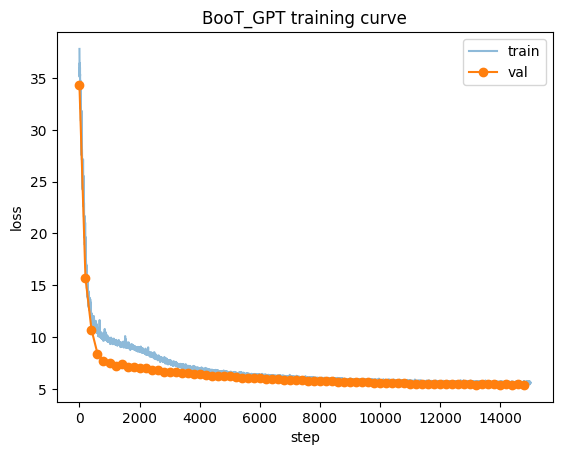

In [ ]:
import matplotlib.pyplot as plt
plt.plot(range(len(train_losses)), train_losses, label="train", alpha=0.5)
plt.plot(val_steps, val_losses, label="val", marker='o')
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.title("BooT_GPT training curve")
plt.savefig("/content/drive/MyDrive/loss_curve.png")
plt.show()

In [ ]:
prompts = ["The history of artificial intelligence", "In recent scientific research,", "The economy of the United States"]
for p in prompts:
    for temp in [0.6, 0.8, 1.0]:
        tokens = torch.tensor(encoder(p)).unsqueeze(0).to(device)
        out = model.generate(tokens, max_new_tokens=100, temperature=temp, top_k=40)
        print(f"--- prompt: '{p}' | temp={temp} ---")
        print(decoder(out[0].tolist()))
        print()

--- prompt: 'The history of artificial intelligence' | temp=0.6 ---
The history of artificial intelligence, including the most exciting, and a variety of conditions.
This article was published in the journal Nature Communications.
"This article discusses the first book is that the first time in the second language, because it has been suggested that their language is a series of language, and the second language as a standard language.
"It is a good idea to use the language, but it is not a problem, but we want to do it. The language is not all the meaning of language is

--- prompt: 'The history of artificial intelligence' | temp=0.8 ---
The history of artificial intelligence, is at least, and in its ability to work at any time of the human mind. The authors have been developed as a way to make a problem and a good life-solving, but they are more likely to be effective for people who are overweight in need. The results are the best way to make it easier to take a lot of good things to

In [ ]:
user_input = input("You: ")

for char in user_input:
    tokens = torch.tensor(encoder(char)).unsqueeze(0).to(device)
    out = model.generate(tokens, max_new_tokens=100, temperature=temp, top_k=40)

# what you want instead:
tokens = torch.tensor(encoder(user_input)).unsqueeze(0).to(device)
out = model.generate(tokens, max_new_tokens=100, temperature=0.8, top_k=40)
print(decoder(out[0].tolist()))

You: hello, how are you?
hello, how are you?
- What will you need?
- What questions are the information and how to use the information you?
- How to use?
- What are you trying to learn about your feedback?
- How?
- How does the data?
- What is a digital camera? How will you tell you what is the information you can?
You can also be useful when it is possible to understand the data?
- What should you do the data to use?
- What
